<a href="https://colab.research.google.com/github/bartlos-1/deforestation-prediction/blob/main/Deforestation_Model_Pipeline.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import folium
import numpy as np
import ee
import xgboost as xgb
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from sklearn.utils import resample
from scipy.ndimage import gaussian_filter

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
# Initialize Earth Engine
ee.Authenticate()
ee.Initialize(project = 'deforestation-450200')



In [3]:
roi = ee.Geometry.Polygon([
    [
        [-122.8, 48.9],
        [-113.5, 48.9],
        [-113.5, 54.5],
        [-122.8, 54.5],
        [-122.8, 48.9]
    ]
])

In [4]:
# Function to get median composite
def get_composite(start, end):
    return (
        ee.ImageCollection("COPERNICUS/S2")
        .filterBounds(roi)
        .filterDate(start, end)
        .filterMetadata("CLOUDY_PIXEL_PERCENTAGE", "less_than", 20)
        .select(["B2", "B3", "B4", "B8"])
        .median()
        .clip(roi)
    )

# Early and late composites
early = get_composite("2015-01-01", "2016-12-31")
late = get_composite("2022-01-01", "2023-12-31")

/usr/local/lib/python3.11/dist-packages/ee/deprecation.py:207: DeprecationWarning: 

Attention required for COPERNICUS/S2! You are using a deprecated asset.
To make sure your code keeps working, please update it.
Learn more: https://developers.google.com/earth-engine/datasets/catalog/COPERNICUS_S2

  warnings.warn(warning, category=DeprecationWarning)


In [5]:
# Delta bands
delta_b4 = late.select("B4").subtract(early.select("B4")).rename("delta_B4")
delta_b8 = late.select("B8").subtract(early.select("B8")).rename("delta_B8")
ndvi_early = early.normalizedDifference(["B8", "B4"]).rename("NDVI_early")
ndvi_late = late.normalizedDifference(["B8", "B4"]).rename("NDVI_late")
delta_ndvi = ndvi_late.subtract(ndvi_early).rename("delta_NDVI")
# NDWI delta (moisture change)
ndwi_early = early.normalizedDifference(["B3", "B8"]).rename("NDWI_early")
ndwi_late = late.normalizedDifference(["B3", "B8"]).rename("NDWI_late")
delta_ndwi = ndwi_late.subtract(ndwi_early).rename("delta_NDWI")
# Full composite and vegetation indices
composite = get_composite("2015-01-01", "2023-12-31")
ndvi = composite.normalizedDifference(["B8", "B4"]).rename("NDVI")
ndwi = composite.normalizedDifference(["B3", "B8"]).rename("NDWI")


In [6]:
# Forest mask
gfc = ee.Image("UMD/hansen/global_forest_change_2023_v1_11").clip(roi)
treecover = gfc.select("treecover2000")
lossyear = gfc.select("lossyear")
loss = gfc.select("loss")        # 1 = forest loss occurred
gain = gfc.select("gain")        # 1 = forest gain occurred





In [7]:
# Elevation and slope
dem = ee.Image("USGS/SRTMGL1_003").select("elevation")
slope = ee.Terrain.slope(dem).rename("slope")
# NDVI texture (standard deviation)
ndvi_stddev_3x3 = ndvi.reduceNeighborhood(
    reducer=ee.Reducer.stdDev(),
    kernel=ee.Kernel.square(1) # 3x3 window
).rename("NDVI_stddev_3x3")

ndvi_stddev_5x5 = ndvi.reduceNeighborhood(
    reducer=ee.Reducer.stdDev(),
    kernel=ee.Kernel.square(2)  # 5x5 window
).rename("NDVI_stddev_5x5")

# Slope texture (standard deviation)
slope_stddev_3x3 = slope.reduceNeighborhood(
    reducer=ee.Reducer.stdDev(),
    kernel=ee.Kernel.square(1)
).rename("slope_stddev_3x3")

slope_stddev_5x5 = slope.reduceNeighborhood(
    reducer=ee.Reducer.stdDev(),
    kernel=ee.Kernel.square(2)
).rename("slope_stddev_5x5")

enhanced_image = composite \
    .addBands(ndvi) \
    .addBands(ndwi) \
    .addBands(delta_b4) \
    .addBands(delta_b8) \
    .addBands(delta_ndvi) \
    .addBands(dem.rename("elevation")) \
    .addBands(slope) \
    .addBands(ndvi_stddev_3x3) \
    .addBands(ndvi_stddev_5x5) \
    .addBands(slope_stddev_3x3) \
    .addBands(slope_stddev_5x5) \
    .addBands(delta_ndwi) \
    .addBands(gain.rename("gain")) \
    .addBands(loss.rename("loss"))
masked_image = enhanced_image.updateMask(treecover.gte(30))

In [8]:
def export_sample_to_drive_tiled(image, bands, base_roi, tile_count=2, scale=1000, num_samples=2000):
    coords = base_roi.bounds().coordinates().get(0).getInfo()
    xmin, ymin = coords[0][0], coords[0][1]
    xmax, ymax = coords[2][0], coords[2][1]

    x_step = (xmax - xmin) / tile_count
    y_step = (ymax - ymin) / tile_count

    lossyear = ee.Image("UMD/hansen/global_forest_change_2023_v1_11").select("lossyear")
    image = image.addBands(lossyear.rename("lossyear"))
    loss = gfc.select("loss")
    gain = gfc.select("gain")
    image = image.addBands(loss.rename("loss")).addBands(gain.rename("gain"))



    task_id = 1
    for i in range(tile_count):
        for j in range(tile_count):
            tile = ee.Geometry.Rectangle([
                xmin + j * x_step,
                ymin + i * y_step,
                xmin + (j + 1) * x_step,
                ymin + (i + 1) * y_step
            ])

            # Sample all forested pixels — filter/label in Python later
            sample = image.select(bands + ["loss"]) \
                .sample(region=tile, scale=scale, numPixels=num_samples, geometries=True, seed=task_id*100) \
                .limit(num_samples)
            task = ee.batch.Export.table.toDrive(
                collection=sample,
                description=f"tile_export_{task_id}",
                folder="earth_engine",
                fileNamePrefix=f"deforestation_tile_{task_id}",
                fileFormat="CSV"
            )
            task.start()
            print(f"✅ Exported tile {task_id} (all forest samples)")
            task_id += 1

    print("🚀 All exports started — label in pandas after download.")




In [9]:
bands = ["B2", "B3", "B4", "B8", "NDVI", "NDWI",
         "delta_B4", "delta_B8", "delta_NDVI",
         "delta_NDWI", "elevation", "slope","gain","NDVI_stddev_3x3","NDVI_stddev_5x5",
         "slope_stddev_3x3","slope_stddev_5x5", "lossyear"]


In [19]:
# Export sample data to Google Drive
# Export 4 tiles (2x2 grid) with 1000 samples each
export_sample_to_drive_tiled(masked_image, bands, roi, tile_count=4)

# After downloading CSV, use pandas to load and process locally
# Example (outside EE):
# import pandas as pd
# df = pd.read_csv("deforestation_data.csv")
# X = df[bands].values
# y = (df["lossyear"] >= 5).astype(int).values  # 5+ corresponds to year 2005+

✅ Exported tile 1 (all forest samples)
✅ Exported tile 2 (all forest samples)
✅ Exported tile 3 (all forest samples)
✅ Exported tile 4 (all forest samples)
✅ Exported tile 5 (all forest samples)
✅ Exported tile 6 (all forest samples)
✅ Exported tile 7 (all forest samples)
✅ Exported tile 8 (all forest samples)
✅ Exported tile 9 (all forest samples)
✅ Exported tile 10 (all forest samples)
✅ Exported tile 11 (all forest samples)
✅ Exported tile 12 (all forest samples)
✅ Exported tile 13 (all forest samples)
✅ Exported tile 14 (all forest samples)
✅ Exported tile 15 (all forest samples)
✅ Exported tile 16 (all forest samples)
🚀 All exports started — label in pandas after download.


In [10]:
import pandas as pd
import glob
import numpy as np

csv_files = glob.glob("/content/drive/MyDrive/earth_engine/deforestation_tile_*.csv")
df_list = [pd.read_csv(file) for file in csv_files]
df = pd.concat(df_list, ignore_index=True)
# Extract lon/lat from geometry column
def extract_coords(geom_str):
    try:
        geom = ast.literal_eval(geom_str)  # safely parse string to dict
        lon, lat = geom["coordinates"]
        return pd.Series({"longitude": lon, "latitude": lat})
    except:
        return pd.Series({"longitude": None, "latitude": None})

# Apply to DataFrame
coords_df = df[".geo"].apply(extract_coords)
df = pd.concat([df, coords_df], axis=1)

# ✅ Fix nulls and assign label

y = df["loss"].astype(int)
  # Convert to NumPy
X = df[bands].values  # Same row count as y


print(f"Total samples: {len(df)}")
print(f"Deforestation samples: {np.sum(y == 1)}")
print(f"No deforestation samples: {np.sum(y == 0)}")
print(df.columns.tolist())


Total samples: 16071
Deforestation samples: 6593
No deforestation samples: 9478
['system:index', 'B2', 'B3', 'B4', 'B8', 'NDVI', 'NDVI_stddev_3x3', 'NDVI_stddev_5x5', 'NDWI', 'delta_B4', 'delta_B8', 'delta_NDVI', 'delta_NDWI', 'elevation', 'gain', 'loss', 'lossyear', 'slope', 'slope_stddev_3x3', 'slope_stddev_5x5', '.geo', 'longitude', 'latitude']


In [11]:
from sklearn.model_selection import train_test_split
from sklearn.utils import resample

# Split classes
X_defor = X[y == 1]
X_nondefor = X[y == 0]

# Downsample non-deforestation to match deforestation count
X_nondefor_down, y_nondefor = resample(
    X_nondefor, y[y == 0],
    replace=False,
    n_samples=len(X_defor),
    random_state=42
)

# Combine balanced dataset
X_bal = np.vstack([X_defor, X_nondefor_down])
y_bal = np.concatenate([y[y == 1], y_nondefor])



X_train, X_test, y_train, y_test = train_test_split(X_bal, y_bal, test_size=0.2, random_state=42)



In [12]:
import xgboost as xgb
from sklearn.metrics import accuracy_score

classifier_model = xgb.XGBClassifier(
    n_estimators=300,
    max_depth=6,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    min_child_weight=5,
    gamma=0.1,
    eval_metric='logloss',
    use_label_encoder=False
)


classifier_model.fit(X_train, y_train, eval_set=[(X_test, y_test)], verbose=True)

y_pred = classifier_model.predict(X_test)
print(f"✅ XGBoost Accuracy: {accuracy_score(y_test, y_pred):.2f}")



[0]	validation_0-logloss:0.68424
[1]	validation_0-logloss:0.67624
[2]	validation_0-logloss:0.66925
[3]	validation_0-logloss:0.66143
[4]	validation_0-logloss:0.65421
[5]	validation_0-logloss:0.64894


/usr/local/lib/python3.11/dist-packages/xgboost/core.py:158: UserWarning: [22:05:23] WARNING: /workspace/src/learner.cc:740: 
Parameters: { "use_label_encoder" } are not used.

  warnings.warn(smsg, UserWarning)


[6]	validation_0-logloss:0.64432
[7]	validation_0-logloss:0.63973
[8]	validation_0-logloss:0.63599
[9]	validation_0-logloss:0.63303
[10]	validation_0-logloss:0.62886
[11]	validation_0-logloss:0.62540
[12]	validation_0-logloss:0.62176
[13]	validation_0-logloss:0.61831
[14]	validation_0-logloss:0.61471
[15]	validation_0-logloss:0.61179
[16]	validation_0-logloss:0.60869
[17]	validation_0-logloss:0.60605
[18]	validation_0-logloss:0.60325
[19]	validation_0-logloss:0.60108
[20]	validation_0-logloss:0.59885
[21]	validation_0-logloss:0.59717
[22]	validation_0-logloss:0.59484
[23]	validation_0-logloss:0.59285
[24]	validation_0-logloss:0.59056
[25]	validation_0-logloss:0.58863
[26]	validation_0-logloss:0.58648
[27]	validation_0-logloss:0.58491
[28]	validation_0-logloss:0.58293
[29]	validation_0-logloss:0.58140
[30]	validation_0-logloss:0.58009
[31]	validation_0-logloss:0.57868
[32]	validation_0-logloss:0.57702
[33]	validation_0-logloss:0.57554
[34]	validation_0-logloss:0.57440
[35]	validation_0-

In [24]:
from sklearn.metrics import accuracy_score
import xgboost as xgb

# Define all model configs
configs = {
    "Conservative": {
        "n_estimators": 1000,
        "max_depth": 4,
        "learning_rate": 0.01,
        "subsample": 0.9,
        "colsample_bytree": 0.9,
        "min_child_weight": 10,
        "gamma": 1
    },
    "Aggressive": {
        "n_estimators": 500,
        "max_depth": 10,
        "learning_rate": 0.03,
        "subsample": 0.7,
        "colsample_bytree": 0.6,
        "min_child_weight": 3,
        "gamma": 0
    },
    "Balanced": {
        "n_estimators": 300,
        "max_depth": 6,
        "learning_rate": 0.05,
        "subsample": 0.8,
        "colsample_bytree": 0.8,
        "min_child_weight": 5,
        "gamma": 0.1
    }
}

results = {}

# Test each config
for name, params in configs.items():
    print(f"\n🧪 Testing config: {name}")

    model = xgb.XGBClassifier(
        **params,
        eval_metric='logloss',
        use_label_encoder=False
    )

    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    acc = accuracy_score(y_test, y_pred)

    print(f"✅ Accuracy for {name}: {acc:.4f}")
    results[name] = acc

# Summary
print("\n📊 Summary of Accuracies:")
for name, acc in results.items():
    print(f"{name}: {acc:.4f}")



🧪 Testing config: Conservative


/usr/local/lib/python3.11/dist-packages/xgboost/core.py:158: UserWarning: [20:13:17] WARNING: /workspace/src/learner.cc:740: 
Parameters: { "use_label_encoder" } are not used.

  warnings.warn(smsg, UserWarning)


✅ Accuracy for Conservative: 0.7293

🧪 Testing config: Aggressive


/usr/local/lib/python3.11/dist-packages/xgboost/core.py:158: UserWarning: [20:13:19] WARNING: /workspace/src/learner.cc:740: 
Parameters: { "use_label_encoder" } are not used.

  warnings.warn(smsg, UserWarning)


✅ Accuracy for Aggressive: 0.7381

🧪 Testing config: Balanced


/usr/local/lib/python3.11/dist-packages/xgboost/core.py:158: UserWarning: [20:13:23] WARNING: /workspace/src/learner.cc:740: 
Parameters: { "use_label_encoder" } are not used.

  warnings.warn(smsg, UserWarning)


✅ Accuracy for Balanced: 0.7445

📊 Summary of Accuracies:
Conservative: 0.7293
Aggressive: 0.7381
Balanced: 0.7445


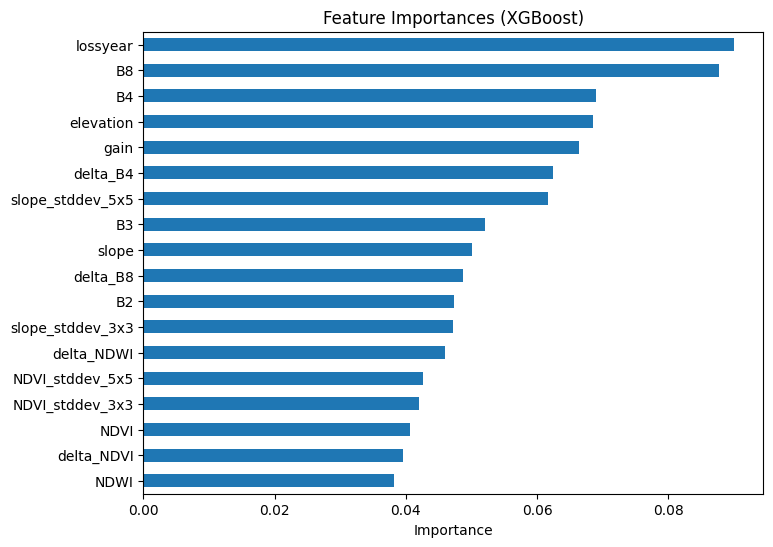

In [40]:
import matplotlib.pyplot as plt
import pandas as pd

# After fitting your best model
importances = model.feature_importances_
feat_names = bands  # same list you used

pd.Series(importances, index=feat_names).sort_values().plot(kind='barh', figsize=(8, 6))
plt.title("Feature Importances (XGBoost)")
plt.xlabel("Importance")
plt.show()

In [53]:
import folium
import numpy as np
from scipy.ndimage import gaussian_filter
from ipywidgets import interact, FloatSlider
from IPython.display import display

# 📍 Latitude and longitude (already extracted from your df)
lats = df["latitude"].values
lons = df["longitude"].values

# 🧠 Model probabilities
probs = model.predict_proba(df[bands])[:, 1]  # Probability of deforestation

# 📍 Bin configuration
lat_bins = np.linspace(48, 55, 150)
lon_bins = np.linspace(-125, -105, 150)

# 🎯 Heatmap generator function with thresholds as arguments
def generate_heatmap(thresh_1=0.3, thresh_2=0.5, thresh_3=0.7):
    # 📊 Create 2D histogram with smoothing
    heatmap_grid, _, _ = np.histogram2d(lats, lons, bins=[lat_bins, lon_bins], weights=probs)
    counts, _, _ = np.histogram2d(lats, lons, bins=[lat_bins, lon_bins])
    avg_probs = np.divide(heatmap_grid, counts, out=np.zeros_like(heatmap_grid), where=counts != 0)
    smoothed_probs = gaussian_filter(avg_probs, sigma=1.5)

    # 🗺️ Create the folium map
    m = folium.Map(location=[52.5, -115], zoom_start=6, tiles='cartodbpositron')

    # 🟠 Draw colored circles based on risk thresholds
    for i in range(smoothed_probs.shape[0]):
        for j in range(smoothed_probs.shape[1]):
            prob = smoothed_probs[i, j]
            if prob >= thresh_1:
                lat = (lat_bins[i] + lat_bins[i + 1]) / 2
                lon = (lon_bins[j] + lon_bins[j + 1]) / 2
                radius = prob * 15

                # Color based on thresholds
                if prob >= thresh_3:
                    color = "darkred"
                elif prob >= thresh_2:
                    color = "orangered"
                else:
                    color = "orange"

                folium.CircleMarker(
                    location=[lat, lon],
                    radius=radius,
                    color=None,
                    fill=True,
                    fill_color=color,
                    fill_opacity=0.5,
                    tooltip=f"Risk: {prob:.2f}"
                ).add_to(m)

    display(m)

# 🧩 Sliders to adjust thresholds
interact(
    generate_heatmap,
    thresh_1=FloatSlider(value=0.3, min=0.0, max=1.0, step=0.01, description='Low Risk'),
    thresh_2=FloatSlider(value=0.5, min=0.0, max=1.0, step=0.01, description='Med Risk'),
    thresh_3=FloatSlider(value=0.7, min=0.0, max=1.0, step=0.01, description='High Risk'),
);



interactive(children=(FloatSlider(value=0.3, description='Low Risk', max=1.0, step=0.01), FloatSlider(value=0.…